In [1]:

# Diagnóstico inicial de la Sumativa 1
# Verificamos entorno y archivo original

import sys
import hashlib
from pathlib import Path
from importlib.metadata import version, PackageNotFoundError

# Ubicación relativa desde la carpeta notebooks
ruta_csv = Path("../data/raw/weatherAUS.csv")

print("=== ENTORNO PYTHON ===")
print("Python:", sys.version.split()[0])
print("Ejecutable:", sys.executable)
print("Carpeta actual:", Path.cwd())

print("\n=== BIBLIOTECAS ===")
for paquete in ["pandas", "numpy", "scipy", "matplotlib"]:
    try:
        print(f"{paquete}: {version(paquete)}")
    except PackageNotFoundError:
        print(f"{paquete}: NO INSTALADO")

print("\n=== VERIFICACIÓN DEL DATASET ===")
print("Archivo encontrado:", ruta_csv.is_file())

if ruta_csv.is_file():

    sha256 = hashlib.sha256()

    with ruta_csv.open("rb") as archivo:
        for bloque in iter(
            lambda: archivo.read(1024 * 1024), b""
        ):
            sha256.update(bloque)

    huella_actual = sha256.hexdigest()

    huella_benja = (
        "573fd715cd69fcacc4df32024d823b450ae3edaae7e8ff2eeb623adbed424014"
    )

    print("Tamaño en bytes:", ruta_csv.stat().st_size)
    print("SHA-256:", huella_actual)
    print("Coincide con Formativa 1:", huella_actual == huella_benja)


=== ENTORNO PYTHON ===
Python: 3.13.0
Ejecutable: C:\Users\jguai\Documents\proyecto-grupo7-mcdi500\.venv\Scripts\python.exe
Carpeta actual: C:\Users\jguai\Proyectos\UNAB\MCDI501\Proyecto-Lluvias-Australia-Grupo7\notebooks

=== BIBLIOTECAS ===
pandas: 3.0.5
numpy: 2.5.3
scipy: 1.18.1
matplotlib: 3.11.1

=== VERIFICACIÓN DEL DATASET ===
Archivo encontrado: True
Tamaño en bytes: 14094055
SHA-256: 573fd715cd69fcacc4df32024d823b450ae3edaae7e8ff2eeb623adbed424014
Coincide con Formativa 1: True


In [2]:

# 1. Carga inicial del dataset Weather Australia

import pandas as pd
from pathlib import Path

# Ubicación del archivo original
ruta_csv = Path("../data/raw/weatherAUS.csv")

# Cargar el archivo CSV
df_original = pd.read_csv(ruta_csv)

# Crear una copia independiente para trabajar
df = df_original.copy(deep=True)

# Convertir la columna Date a formato fecha
df["Date"] = pd.to_datetime(
    df["Date"],
    format="%Y-%m-%d"
)

# Verificar dimensiones y características principales
print("=== INFORMACIÓN GENERAL DEL DATASET ===")
print("Observaciones:", df.shape[0])
print("Variables:", df.shape[1])
print("Localidades:", df["Location"].nunique())
print("Fecha inicial:", df["Date"].min().date())
print("Fecha final:", df["Date"].max().date())

print("\n=== DISTRIBUCIÓN DE RAINTOMORROW ===")
print(df["RainTomorrow"].value_counts(dropna=False))

print("\n=== PRIMEROS CINCO REGISTROS ===")
display(df.head())


=== INFORMACIÓN GENERAL DEL DATASET ===
Observaciones: 145460
Variables: 23
Localidades: 49
Fecha inicial: 2007-11-01
Fecha final: 2017-06-25

=== DISTRIBUCIÓN DE RAINTOMORROW ===
RainTomorrow
No     110316
Yes     31877
NaN      3267
Name: count, dtype: int64

=== PRIMEROS CINCO REGISTROS ===


,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,...,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,...,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,...,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,...,45.0,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,...,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,No


In [3]:

# 2. Estadística descriptiva y asimetría
# Sumativa 1 - Grupo 7

# Variables meteorológicas seleccionadas
variables = [
    "Humidity3pm",
    "Rainfall",
    "Sunshine",
    "Pressure3pm",
    "MaxTemp",
    "MinTemp"
]

# Calcular estadísticas con los datos disponibles
tabla_descriptiva = df[variables].agg([
    "count",
    "mean",
    "median",
    "std",
    "skew",
    "min",
    "max"
]).T

# Identificar valores faltantes por variable
tabla_descriptiva["Faltantes"] = (
    df[variables].isna().sum()
)

tabla_descriptiva["% faltantes"] = (
    df[variables].isna().mean() * 100
)

# Renombrar las columnas
tabla_descriptiva = tabla_descriptiva.rename(
    columns={
        "count": "n",
        "mean": "Media",
        "median": "Mediana",
        "std": "Desv. estándar",
        "skew": "Asimetría",
        "min": "Mínimo",
        "max": "Máximo"
    }
)

print("=== ESTADÍSTICA DESCRIPTIVA Y ASIMETRÍA ===")
display(tabla_descriptiva.round(2))


=== ESTADÍSTICA DESCRIPTIVA Y ASIMETRÍA ===


,n,Media,Mediana,Desv. estándar,Asimetría,Mínimo,Máximo,Faltantes,% faltantes
Humidity3pm,140953.0,51.54,52.0,20.80,0.03,0.0,100.0,4507,3.10
Rainfall,142199.0,2.36,0.0,8.48,9.84,0.0,371.0,3261,2.24
Sunshine,75625.0,7.61,8.4,3.79,-0.50,0.0,14.5,69835,48.01
Pressure3pm,130432.0,1015.26,1015.2,7.04,-0.05,977.1,1039.6,15028,10.33
MaxTemp,144199.0,23.22,22.6,7.12,0.22,-4.8,48.1,1261,0.87
MinTemp,143975.0,12.19,12.0,6.40,0.02,-8.5,33.9,1485,1.02



### 2.1. Interpretación de las estadísticas descriptivas

Al revisar las variables meteorológicas, encontramos diferencias importantes en sus distribuciones.

La variable `Rainfall` presenta una asimetría positiva bastante marcada (9,84). Su mediana es 0 mm, mientras que la media alcanza 2,36 mm. Esto indica que al menos la mitad de los registros válidos no presenta precipitaciones, aunque también existen días con lluvias considerablemente mayores.

En cambio, `Humidity3pm` y `Pressure3pm` tienen coeficientes de asimetría cercanos a cero (0,03 y -0,05, respectivamente), lo que sugiere distribuciones con poca asimetría global. Esto no significa necesariamente que sigan una distribución normal.

Otro aspecto que nos llamó la atención fue la cantidad de información faltante en `Sunshine`, que alcanza el 48,01 %, y en `Pressure3pm`, con un 10,33 %. Por este motivo, utilizaremos los registros disponibles para cada análisis, sin eliminar de manera general todas las filas incompletas.

Estos resultados son descriptivos y corresponden al conjunto de observaciones agrupadas. Las comparaciones inferenciales principales mantendrán el enfoque por localidad utilizado en la Formativa 1.


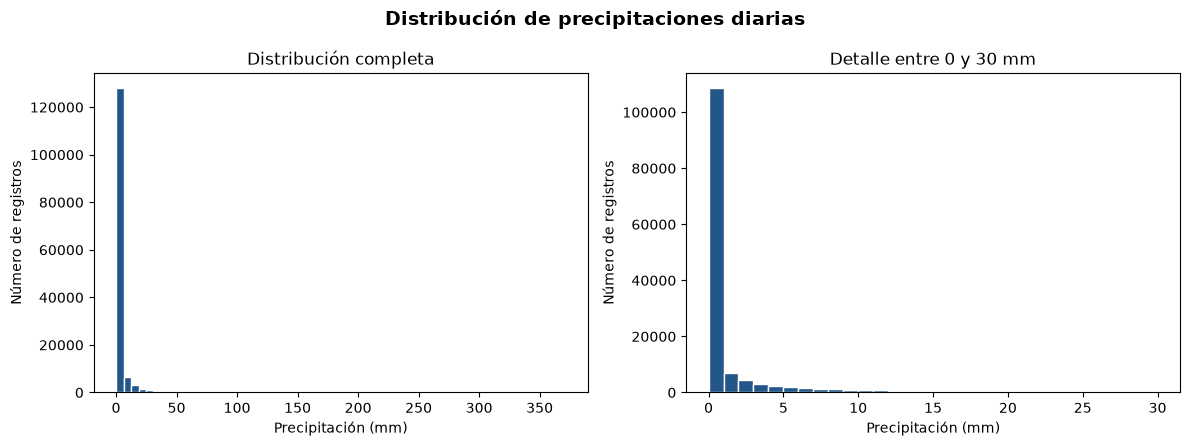

=== RESULTADOS DE RAINFALL ===
Registros válidos: 142199
Media: 2.36 mm
Mediana: 0.00 mm
Asimetría: 9.84
Registros mayores de 30 mm: 2128


In [4]:

# Figura 1. Distribución de precipitaciones
# Sumativa 1 - Grupo 7

import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

# Seleccionar registros con precipitaciones conocidas
lluvia = df["Rainfall"].dropna()

# Crear una figura con dos vistas
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

# Vista 1: distribución completa
ax[0].hist(
    lluvia,
    bins=60,
    color="#235789",
    edgecolor="white"
)

ax[0].set_title("Distribución completa")
ax[0].set_xlabel("Precipitación (mm)")
ax[0].set_ylabel("Número de registros")

# Vista 2: detalle de precipitaciones de 0 a 30 mm
ax[1].hist(
    lluvia,
    bins=np.arange(0, 31, 1),
    color="#235789",
    edgecolor="white"
)

ax[1].set_title("Detalle entre 0 y 30 mm")
ax[1].set_xlabel("Precipitación (mm)")
ax[1].set_ylabel("Número de registros")

# Título general
fig.suptitle(
    "Distribución de precipitaciones diarias",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

# Guardar en la estructura oficial del repositorio
carpeta_figuras = Path("../results/02_sumativa1/figures")
carpeta_figuras.mkdir(parents=True, exist_ok=True)

fig.savefig(
    carpeta_figuras / "figura01_histograma_rainfall.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Mostrar estadísticas de referencia
print("=== RESULTADOS DE RAINFALL ===")
print("Registros válidos:", len(lluvia))
print(f"Media: {lluvia.mean():.2f} mm")
print(f"Mediana: {lluvia.median():.2f} mm")
print(f"Asimetría: {lluvia.skew():.2f}")
print("Registros mayores de 30 mm:", (lluvia > 30).sum())



### 2.2. Distribución de las precipitaciones

Los histogramas muestran que la mayor parte de los registros se concentra en valores bajos de precipitación, especialmente alrededor de 0 mm.

La variable `Rainfall` presenta una media de 2,36 mm y una mediana de 0 mm, lo que evidencia una distribución asimétrica. Esto también se refleja en su coeficiente de asimetría positiva de 9,84.

De los 142.199 registros disponibles, 2.128 presentan precipitaciones superiores a 30 mm. Estos valores explican parte de la cola derecha de la distribución, pero no se consideran errores únicamente por ser elevados.

El gráfico ampliado permite observar mejor la concentración de registros con precipitaciones bajas, mientras que el gráfico completo muestra la amplitud de los valores registrados.

Estos resultados indican que, para describir las precipitaciones, es importante considerar tanto la media como la mediana, ya que la primera puede verse influida por los valores extremos.


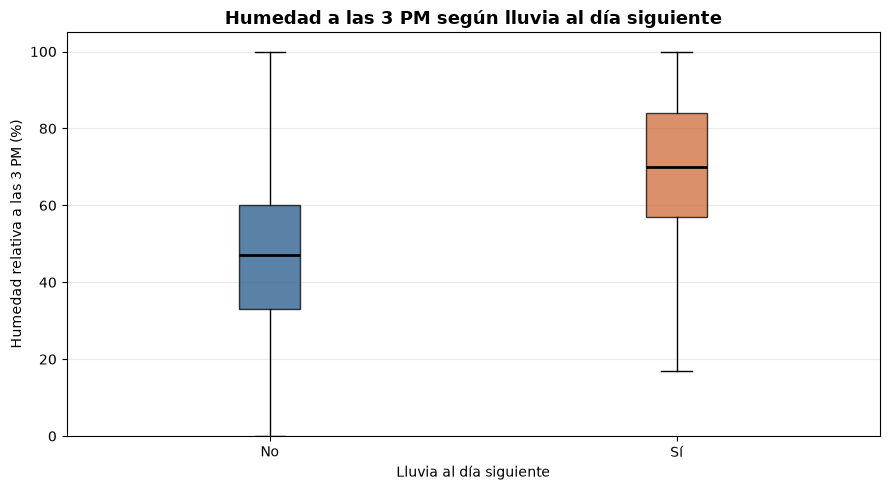

=== HUMEDAD SEGÚN LLUVIA POSTERIOR ===


,count,mean,median,std
RainTomorrow,,,,
No,107670,46.51,47.0,18.49
Yes,30913,68.80,70.0,19.04


Observaciones utilizadas: 138583
Diferencia de medias agrupadas: 22.29 puntos porcentuales


In [5]:

# Figura 2. Humedad a las 3 PM según lluvia al día siguiente
# Sumativa 1 - Grupo 7

import matplotlib.pyplot as plt
from pathlib import Path

# Seleccionar solamente registros con ambas variables conocidas
datos_boxplot = df.loc[
    df["RainTomorrow"].isin(["No", "Yes"]),
    ["Humidity3pm", "RainTomorrow"]
].dropna()

# Separar los registros en dos grupos
grupo_no = datos_boxplot.loc[
    datos_boxplot["RainTomorrow"] == "No",
    "Humidity3pm"
]

grupo_si = datos_boxplot.loc[
    datos_boxplot["RainTomorrow"] == "Yes",
    "Humidity3pm"
]

# Crear el gráfico
fig, ax = plt.subplots(figsize=(9, 5))

cajas = ax.boxplot(
    [grupo_no, grupo_si],
    tick_labels=["No", "Sí"],
    patch_artist=True,
    showfliers=False,
    medianprops={"color": "black", "linewidth": 2}
)

# Colores para identificar cada grupo
colores = ["#235789", "#CE6C39"]

for caja, color in zip(cajas["boxes"], colores):
    caja.set_facecolor(color)
    caja.set_alpha(0.75)

# Títulos y etiquetas
ax.set_title(
    "Humedad a las 3 PM según lluvia al día siguiente",
    fontsize=13,
    fontweight="bold"
)

ax.set_xlabel("Lluvia al día siguiente")
ax.set_ylabel("Humedad relativa a las 3 PM (%)")
ax.set_ylim(0, 105)
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

# Guardar figura en el repositorio
carpeta_figuras = Path("../results/02_sumativa1/figures")
carpeta_figuras.mkdir(parents=True, exist_ok=True)

fig.savefig(
    carpeta_figuras / "figura02_boxplot_humedad.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Calcular estadísticas de cada grupo
resumen_humedad = (
    datos_boxplot
    .groupby("RainTomorrow")["Humidity3pm"]
    .agg(["count", "mean", "median", "std"])
    .reindex(["No", "Yes"])
)

print("=== HUMEDAD SEGÚN LLUVIA POSTERIOR ===")
display(resumen_humedad.round(2))

print("Observaciones utilizadas:", len(datos_boxplot))

diferencia = grupo_si.mean() - grupo_no.mean()

print(
    f"Diferencia de medias agrupadas: "
    f"{diferencia:.2f} puntos porcentuales"
)



### 2.3. Comparación de humedad según lluvia posterior

Al comparar la humedad relativa a las 3 PM, observamos diferencias entre los registros con y sin lluvia al día siguiente.

En los registros asociados con lluvia posterior, la humedad media alcanza el 68,80 %, mientras que en aquellos sin lluvia es de 46,51 %. La diferencia entre ambas medias es de 22,29 puntos porcentuales.

Las medianas también muestran una diferencia importante: 70 % cuando posteriormente llueve y 47 % cuando no. Esta separación se observa claramente en el diagrama de caja.

Para esta comparación utilizamos 138.583 registros con información disponible en ambas variables.

Estos resultados muestran una asociación descriptiva entre la humedad vespertina y la ocurrencia de lluvia al día siguiente, pero no permiten establecer una relación causal.

Es importante señalar que esta comparación agrupa todos los registros. En la etapa inferencial mantendremos el enfoque de la Formativa 1, calculando primero las diferencias dentro de cada localidad y dando el mismo peso a las 49 localidades.


=== MATRIZ DE CORRELACIONES DE SPEARMAN ===


,MinTemp,MaxTemp,Temp3pm,Humidity3pm,Pressure3pm,Rainfall,Sunshine
MinTemp,1.000,0.738,0.709,0.030,-0.469,0.022,0.113
MaxTemp,0.738,1.000,0.984,-0.460,-0.445,-0.298,0.499
Temp3pm,0.709,0.984,1.000,-0.509,-0.408,-0.305,0.521
Humidity3pm,0.030,-0.460,-0.509,1.000,0.058,0.444,-0.620
Pressure3pm,-0.469,-0.445,-0.408,0.058,1.000,-0.063,-0.051
Rainfall,0.022,-0.298,-0.305,0.444,-0.063,1.000,-0.401
Sunshine,0.113,0.499,0.521,-0.620,-0.051,-0.401,1.000



=== OBSERVACIONES DISPONIBLES POR PAR ===


,MinTemp,MaxTemp,Temp3pm,Humidity3pm,Pressure3pm,Rainfall,Sunshine
MinTemp,143975,143579,141419,140528,130105,141712,74980
MaxTemp,143579,144199,141589,140696,130187,141729,75011
Temp3pm,141419,141589,141851,140953,128932,139453,74745
Humidity3pm,140528,140696,140953,140953,128110,138569,74497
Pressure3pm,130105,130187,128932,128110,130432,128206,74934
Rainfall,141712,141729,139453,138569,128206,142199,74379
Sunshine,74980,75011,74745,74497,74934,74379,75625


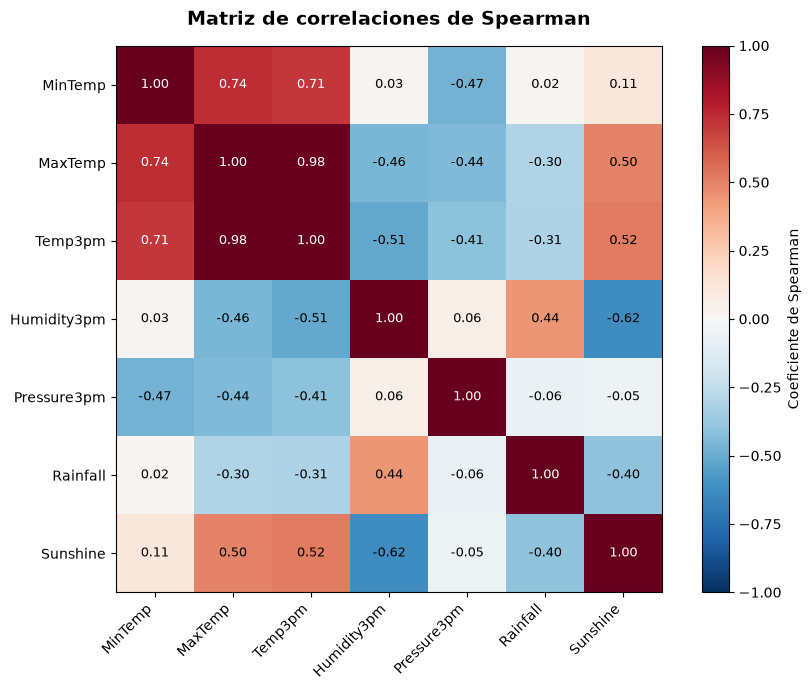

In [6]:

# Figura 3. Matriz de correlaciones de Spearman
# Sumativa 1 - Grupo 7

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Mismas siete variables utilizadas por Benja
variables_corr = [
    "MinTemp",
    "MaxTemp",
    "Temp3pm",
    "Humidity3pm",
    "Pressure3pm",
    "Rainfall",
    "Sunshine"
]

# Calcular correlaciones de Spearman
matriz_corr = df[variables_corr].corr(
    method="spearman"
)

# Número de observaciones disponibles por cada par
datos_disponibles = (
    df[variables_corr].notna().astype("int64")
)

n_pares = datos_disponibles.T.dot(datos_disponibles)

print("=== MATRIZ DE CORRELACIONES DE SPEARMAN ===")
display(matriz_corr.round(3))

print("\n=== OBSERVACIONES DISPONIBLES POR PAR ===")
display(n_pares)

# Crear mapa de calor
fig, ax = plt.subplots(figsize=(9, 7))

imagen = ax.imshow(
    matriz_corr,
    cmap="RdBu_r",
    vmin=-1,
    vmax=1
)

# Etiquetas
ax.set_xticks(range(len(variables_corr)))
ax.set_yticks(range(len(variables_corr)))

ax.set_xticklabels(variables_corr, rotation=45, ha="right")
ax.set_yticklabels(variables_corr)

# Mostrar coeficientes dentro de cada celda
for i in range(len(variables_corr)):
    for j in range(len(variables_corr)):
        valor = matriz_corr.iloc[i, j]

        ax.text(
            j, i, f"{valor:.2f}",
            ha="center",
            va="center",
            fontsize=9,
            color="white" if abs(valor) > 0.65 else "black"
        )

ax.set_title(
    "Matriz de correlaciones de Spearman",
    fontsize=14,
    fontweight="bold",
    pad=15
)

fig.colorbar(
    imagen,
    ax=ax,
    label="Coeficiente de Spearman"
)

plt.tight_layout()

# Guardar figura y tablas
carpeta_resultados = Path("../results/02_sumativa1")
carpeta_figuras = carpeta_resultados / "figures"
carpeta_tablas = carpeta_resultados / "tables"

carpeta_figuras.mkdir(parents=True, exist_ok=True)
carpeta_tablas.mkdir(parents=True, exist_ok=True)

fig.savefig(
    carpeta_figuras / "figura03_correlaciones.png",
    dpi=300,
    bbox_inches="tight"
)

matriz_corr.to_csv(
    carpeta_tablas / "matriz_correlaciones_spearman.csv"
)

n_pares.to_csv(
    carpeta_tablas / "n_pares_correlaciones.csv"
)

plt.show()



### 2.4. Interpretación de la matriz de correlaciones

Para complementar el análisis exploratorio, calculamos una matriz de correlaciones de Spearman entre siete variables meteorológicas, utilizando los registros disponibles para cada par.

Una de las relaciones más fuertes corresponde a `MaxTemp` y `Temp3pm`, con un coeficiente de 0,984. Esto indica que ambas temperaturas tienden a aumentar conjuntamente, algo esperable considerando que representan mediciones relacionadas.

También encontramos una correlación negativa de -0,620 entre `Humidity3pm` y `Sunshine`. Esto sugiere que los registros con mayor humedad vespertina tienden a presentar menos horas de sol.

Por otra parte, `Humidity3pm` y `Rainfall` presentan una correlación positiva de 0,444, mientras que `Rainfall` y `Sunshine` muestran una correlación negativa de -0,401.

Un aspecto importante es que no todas las correlaciones se calcularon con la misma cantidad de observaciones. Por ejemplo, la relación entre humedad y horas de sol utiliza 74.497 registros, debido principalmente a los datos faltantes de `Sunshine`.

En general, estos resultados permiten identificar asociaciones entre las variables meteorológicas, pero no demuestran relaciones causales. Además, debemos considerar que los registros provienen de diferentes localidades y períodos, lo que puede influir en las asociaciones observadas.

Estas correlaciones describen las condiciones meteorológicas registradas y no permiten concluir directamente qué variables predicen mejor la lluvia al día siguiente.


In [7]:


# 3. Intervalos de confianza del 95 %
# Medias por localidad - Grupo 7
# Cálculo sin importar SciPy

import pandas as pd
from pathlib import Path

variables_ic = ["Humidity3pm", "MaxTemp", "MinTemp"]

# Una media por cada localidad
medias_locales = df.groupby("Location")[variables_ic].mean()

# Valor crítico t: confianza 95 %, 48 grados de libertad
t_critico = 2.01063475762423

resultados_ic = []

for variable in variables_ic:

    valores = medias_locales[variable].dropna()
    n = len(valores)

    # Verificar que sean las 49 localidades esperadas
    if n != 49:
        raise ValueError(
            f"{variable}: se esperaban 49 localidades, hay {n}"
        )

    media = valores.mean()
    desviacion = valores.std(ddof=1)
    error_estandar = desviacion / (n ** 0.5)

    limite_inferior = media - t_critico * error_estandar
    limite_superior = media + t_critico * error_estandar

    resultados_ic.append({
        "Variable": variable,
        "Localidades": n,
        "Media local": media,
        "Desv. entre localidades": desviacion,
        "Error estándar": error_estandar,
        "IC 95% inferior": limite_inferior,
        "IC 95% superior": limite_superior
    })

tabla_ic = pd.DataFrame(resultados_ic)

print("=== INTERVALOS DE CONFIANZA DEL 95 % ===")
display(tabla_ic.round(3))

# Guardar resultados
carpeta_tablas = Path("../results/02_sumativa1/tables")
carpeta_tablas.mkdir(parents=True, exist_ok=True)

tabla_ic.to_csv(
    carpeta_tablas / "intervalos_medias_localidades.csv",
    index=False,
    encoding="utf-8-sig"
)



=== INTERVALOS DE CONFIANZA DEL 95 % ===


,Variable,Localidades,Media local,Desv. entre localidades,Error estándar,IC 95% inferior,IC 95% superior
0,Humidity3pm,49,51.247,11.217,1.602,48.025,54.469
1,MaxTemp,49,23.388,4.056,0.579,22.223,24.553
2,MinTemp,49,12.259,3.951,0.564,11.124,13.394



### 3.1. Interpretación de los intervalos de confianza

Para estimar las medias meteorológicas, utilizamos las 49 localidades del conjunto de datos como unidades de análisis, siguiendo el procedimiento de la Formativa 1.

Primero calculamos la media de cada variable dentro de cada localidad y posteriormente construimos intervalos de confianza nominales del 95 %, utilizando la distribución t de Student.

Los resultados fueron los siguientes:

- **Humedad a las 3 PM:** media de 51,25 % e intervalo entre 48,02 % y 54,47 %.
- **Temperatura máxima:** media de 23,39 °C e intervalo entre 22,22 °C y 24,55 °C.
- **Temperatura mínima:** media de 12,26 °C e intervalo entre 11,12 °C y 13,39 °C.

A diferencia de los análisis descriptivos anteriores, aquí cada localidad tiene el mismo peso, independientemente de la cantidad de registros disponibles.

Esta decisión permite estudiar las condiciones meteorológicas desde una perspectiva geográfica, evitando que las localidades con más observaciones dominen directamente el promedio.

Sin embargo, los intervalos deben interpretarse con cautela, ya que su validez depende de supuestos estadísticos, especialmente de la independencia aproximada entre localidades. Tampoco podemos asegurar que las 49 localidades constituyan una muestra representativa de toda Australia.

Por lo tanto, consideramos estos intervalos como estimaciones exploratorias condicionadas a los datos y supuestos utilizados.


In [8]:

# 4. Intervalo de confianza para la proporción de lluvia
# Método de Wilson - confianza del 95 %
# Sumativa 1 - Grupo 7

import numpy as np
import pandas as pd
from statistics import NormalDist
from pathlib import Path

# Seleccionar registros con respuesta conocida
lluvia_valida = df.loc[
    df["RainTomorrow"].isin(["Yes", "No"]),
    "RainTomorrow"
]

# Tamaño de la muestra y número de casos con lluvia
n = len(lluvia_valida)
exitos = (lluvia_valida == "Yes").sum()

# Estimación puntual
p = exitos / n

# Valor crítico normal para un IC del 95 %
z = NormalDist().inv_cdf(0.975)

# Calcular intervalo de Wilson
denominador = 1 + (z**2 / n)

centro = (
    p + z**2 / (2 * n)
) / denominador

margen = (
    z / denominador
) * np.sqrt(
    p * (1 - p) / n +
    z**2 / (4 * n**2)
)

limite_inferior = centro - margen
limite_superior = centro + margen

# Mostrar resultados
print("=== PROPORCIÓN DE LLUVIA AL DÍA SIGUIENTE ===")

print("Observaciones válidas:", n)
print("Registros con lluvia:", exitos)
print("Registros excluidos:", len(df) - n)

print(f"Proporción estimada: {p * 100:.4f}%")

print(
    f"IC Wilson del 95%: "
    f"[{limite_inferior * 100:.4f}%; "
    f"{limite_superior * 100:.4f}%]"
)

# Guardar resultados para el informe
tabla_proporcion = pd.DataFrame([{
    "n": n,
    "Registros con lluvia": exitos,
    "Proporción": p,
    "IC 95% inferior": limite_inferior,
    "IC 95% superior": limite_superior,
    "Método": "Wilson"
}])

carpeta_tablas = Path("../results/02_sumativa1/tables")
carpeta_tablas.mkdir(parents=True, exist_ok=True)

tabla_proporcion.to_csv(
    carpeta_tablas / "intervalo_proporcion_lluvia.csv",
    index=False,
    encoding="utf-8-sig"
)


=== PROPORCIÓN DE LLUVIA AL DÍA SIGUIENTE ===
Observaciones válidas: 142193
Registros con lluvia: 31877
Registros excluidos: 3267
Proporción estimada: 22.4181%
IC Wilson del 95%: [22.2021%; 22.6356%]


In [9]:

# 5. Proporción de lluvia por localidad
# Sumativa 1 - Grupo 7

import pandas as pd
from pathlib import Path

# Seleccionar registros con respuesta conocida
datos_validos = df.loc[
    df["RainTomorrow"].isin(["Yes", "No"]),
    ["Location", "RainTomorrow"]
].copy()

# Crear una variable binaria: 1 = lluvia, 0 = no lluvia
datos_validos["lluvia_yes"] = (
    datos_validos["RainTomorrow"] == "Yes"
).astype(int)

# Calcular resultados por localidad
tabla_localidades = (
    datos_validos.groupby("Location")
    .agg(
        n=("lluvia_yes", "size"),
        dias_lluvia=("lluvia_yes", "sum"),
        proporcion=("lluvia_yes", "mean")
    )
)

# Expresar las proporciones en porcentaje
tabla_localidades["porcentaje"] = (
    tabla_localidades["proporcion"] * 100
)

print("=== PROPORCIÓN DE LLUVIA POR LOCALIDAD ===")
display(tabla_localidades.round(2))

# Calcular la media de las proporciones locales
n_localidades = len(tabla_localidades)

assert n_localidades == 49, "Revisar número de localidades"

media_local = tabla_localidades["porcentaje"].mean()

# Intervalo t exploratorio del 95 %
desviacion_local = tabla_localidades["porcentaje"].std(ddof=1)
error_local = desviacion_local / n_localidades**0.5

# Valor crítico t para 48 grados de libertad
t_critico = 2.01063475762423

ic_local_inferior = media_local - t_critico * error_local
ic_local_superior = media_local + t_critico * error_local

print("\n=== RESUMEN GEOGRÁFICO ===")
print("Localidades:", n_localidades)
print(f"Media de proporciones locales: {media_local:.2f}%")
print(f"Proporción agrupada: {p * 100:.2f}%")
print(f"IC t exploratorio del 95%: "
      f"[{ic_local_inferior:.2f}%; {ic_local_superior:.2f}%]")

print("\nLocalidad con menor proporción:")
print(tabla_localidades["porcentaje"].idxmin())

print("\nLocalidad con mayor proporción:")
print(tabla_localidades["porcentaje"].idxmax())

# Guardar resultados
carpeta_tablas = Path("../results/02_sumativa1/tables")
carpeta_tablas.mkdir(parents=True, exist_ok=True)

tabla_localidades.to_csv(
    carpeta_tablas / "proporcion_lluvia_localidades.csv",
    encoding="utf-8-sig"
)


=== PROPORCIÓN DE LLUVIA POR LOCALIDAD ===


,n,dias_lluvia,proporcion,porcentaje
Location,,,,
Adelaide,3090,688,0.22,22.27
Albany,3016,902,0.30,29.91
Albury,3011,618,0.21,20.52
AliceSprings,3031,244,0.08,8.05
BadgerysCreek,2928,583,0.20,19.91
Ballarat,3028,781,0.26,25.79
Bendigo,3034,562,0.19,18.52
Brisbane,3161,709,0.22,22.43
Cairns,2988,950,0.32,31.79



=== RESUMEN GEOGRÁFICO ===
Localidades: 49
Media de proporciones locales: 22.19%
Proporción agrupada: 22.42%
IC t exploratorio del 95%: [20.24%; 24.14%]

Localidad con menor proporción:
Woomera

Localidad con mayor proporción:
Portland



### 3.2. Proporción de lluvia al día siguiente

Para complementar la estimación puntual, calculamos la proporción de registros con lluvia al día siguiente utilizando dos enfoques.

Primero, considerando todos los registros con respuesta conocida, obtuvimos una proporción de 22,42 %, con un intervalo de Wilson del 95 % entre 22,20 % y 22,64 %.

Después calculamos la proporción de lluvia dentro de cada una de las 49 localidades. Al dar el mismo peso a cada localidad, obtuvimos una media de 22,19 %, con un intervalo t exploratorio del 95 % entre 20,24 % y 24,14 %.

La diferencia entre ambos enfoques es pequeña en la estimación puntual, pero más importante en la amplitud de los intervalos. Esto ocurre porque el segundo procedimiento considera la variabilidad entre las proporciones de las localidades, aunque no resuelve completamente la dependencia geográfica.

También encontramos diferencias entre localidades. Woomera presenta la menor proporción de lluvia posterior (6,76 %), mientras que Portland alcanza la mayor (36,55 %).

Estos resultados muestran que las precipitaciones no se distribuyen de manera uniforme entre las localidades del conjunto de datos.

Por lo tanto, los intervalos deben interpretarse considerando sus supuestos, los datos faltantes y las limitaciones de cobertura geográfica. No podemos asumir que representan automáticamente a toda Australia.


In [10]:

# 5. Prueba de hipótesis: humedad y lluvia posterior
# Enfoque por localidades - Grupo 7

import numpy as np
import pandas as pd
from scipy import stats

# Seleccionar registros con información conocida
datos_prueba = df.loc[
    df["RainTomorrow"].isin(["No", "Yes"])
    & df["Humidity3pm"].notna(),
    ["Location", "RainTomorrow", "Humidity3pm"]
].copy()

# Calcular humedad media de cada grupo por localidad
medias_grupo = (
    datos_prueba
    .groupby(["Location", "RainTomorrow"])["Humidity3pm"]
    .mean()
    .unstack()
    .reindex(columns=["No", "Yes"])
)

# Conservar localidades con ambos grupos disponibles
medias_grupo = medias_grupo.dropna()

# Diferencia de humedad: lluvia posterior - sin lluvia
diferencias = medias_grupo["Yes"] - medias_grupo["No"]

# Verificar cantidad de localidades
n_localidades = len(diferencias)

assert n_localidades == 49, (
    f"Se esperaban 49 localidades, hay {n_localidades}"
)

# Prueba t bilateral sobre las diferencias locales
resultado_t = stats.ttest_1samp(
    diferencias,
    popmean=0,
    alternative="two-sided"
)

# Intervalo de confianza del 95 %
ic_diferencia = resultado_t.confidence_interval(
    confidence_level=0.95
)

# Tamaño del efecto: d de Cohen para diferencias
d_cohen = (
    diferencias.mean() /
    diferencias.std(ddof=1)
)

# Mostrar resultados
print("=== PRUEBA T POR LOCALIDADES ===")

print("Localidades utilizadas:", n_localidades)
print("Registros utilizados:", len(datos_prueba))

print(
    f"Diferencia media: {diferencias.mean():.4f} "
    "puntos porcentuales"
)

print(f"Estadístico t: {resultado_t.statistic:.4f}")
print(f"Grados de libertad: {n_localidades - 1}")
print(f"Valor p: {resultado_t.pvalue:.6e}")

print(
    f"IC 95% de la diferencia: "
    f"[{ic_diferencia.low:.4f}; "
    f"{ic_diferencia.high:.4f}]"
)

print(f"Tamaño del efecto (d_z): {d_cohen:.4f}")

# Decisión estadística
alfa = 0.05

if resultado_t.pvalue < alfa:
    print("Decisión: Rechazar H0 al 5%")
else:
    print("Decisión: No rechazar H0 al 5%")


=== PRUEBA T POR LOCALIDADES ===
Localidades utilizadas: 49
Registros utilizados: 138583
Diferencia media: 20.0769 puntos porcentuales
Estadístico t: 25.1461
Grados de libertad: 48
Valor p: 2.747108e-29
IC 95% de la diferencia: [18.4716; 21.6822]
Tamaño del efecto (d_z): 3.5923
Decisión: Rechazar H0 al 5%



### 4.1. Prueba de hipótesis: humedad vespertina y lluvia posterior

Para evaluar la relación entre la humedad a las 3 PM y la ocurrencia de lluvia al día siguiente, realizamos una prueba t de Student sobre las diferencias de humedad calculadas para las 49 localidades.

Planteamos las siguientes hipótesis:

- **H₀:** la media de las diferencias de humedad es igual a cero.
- **H₁:** la media de las diferencias de humedad es distinta de cero.

Se utilizó un nivel de significancia de α = 0,05.

La diferencia media obtenida fue de 20,08 puntos porcentuales, con un estadístico t = 25,15 y 48 grados de libertad. El valor p fue inferior a 0,001.

El intervalo de confianza nominal del 95 % para la diferencia se situó entre 18,47 y 21,68 puntos porcentuales. Además, el tamaño del efecto fue elevado (dᶻ = 3,59).

Como el valor p es menor que 0,05, rechazamos la hipótesis nula bajo los supuestos del contraste.

Estos resultados indican que, en las localidades analizadas, la humedad vespertina tiende a ser mayor en los registros asociados con lluvia al día siguiente.

Sin embargo, esta asociación no demuestra causalidad ni permite afirmar por sí sola que la humedad sea suficiente para predecir precipitaciones.

También debemos considerar que las localidades y los registros meteorológicos pueden presentar dependencia espacial y temporal, lo que limita la interpretación inferencial de la prueba clásica.


In [11]:

# 6. Prueba chi-cuadrado de Pearson
# Asociación entre RainToday y RainTomorrow
# Sumativa 1 - Grupo 7

import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency
from pathlib import Path

# Seleccionar registros con ambas respuestas conocidas
datos_chi = df.loc[
    df["RainToday"].isin(["No", "Yes"])
    & df["RainTomorrow"].isin(["No", "Yes"]),
    ["RainToday", "RainTomorrow"]
].copy()

# Construir tabla de contingencia
tabla_contingencia = pd.crosstab(
    datos_chi["RainToday"],
    datos_chi["RainTomorrow"]
).reindex(
    index=["No", "Yes"],
    columns=["No", "Yes"]
)

print("=== TABLA DE CONTINGENCIA ===")
display(tabla_contingencia)

# Calcular porcentajes dentro de cada categoría de RainToday
porcentajes = (
    tabla_contingencia.div(
        tabla_contingencia.sum(axis=1),
        axis=0
    ) * 100
)

print("\n=== PORCENTAJES POR FILA ===")
display(porcentajes.round(2))

# Prueba chi-cuadrado de Pearson sin corrección de Yates
chi2, p_valor, gl, frecuencias_esperadas = (
    chi2_contingency(
        tabla_contingencia,
        correction=False
    )
)

# Mostrar frecuencias esperadas
tabla_esperada = pd.DataFrame(
    frecuencias_esperadas,
    index=tabla_contingencia.index,
    columns=tabla_contingencia.columns
)

print("\n=== FRECUENCIAS ESPERADAS BAJO H0 ===")
display(tabla_esperada.round(2))

# Tamaño del efecto: V de Cramér
n = tabla_contingencia.to_numpy().sum()

filas, columnas = tabla_contingencia.shape

v_cramer = np.sqrt(
    chi2 / (n * min(filas - 1, columnas - 1))
)

print("\n=== RESULTADOS CHI-CUADRADO ===")

print("Observaciones utilizadas:", n)
print("Registros excluidos:", len(df) - n)

print(f"Chi-cuadrado: {chi2:.4f}")
print("Grados de libertad:", gl)
print(f"Valor p: {p_valor:.6e}")
print(f"V de Cramér: {v_cramer:.4f}")

print(
    "Frecuencia esperada mínima:",
    round(frecuencias_esperadas.min(), 2)
)

print(
    "Lluvia mañana si llueve hoy:",
    f"{porcentajes.loc['Yes', 'Yes']:.2f}%"
)

print(
    "Lluvia mañana si no llueve hoy:",
    f"{porcentajes.loc['No', 'Yes']:.2f}%"
)

# Decisión estadística
alfa = 0.05

if p_valor < alfa:
    print("Decisión: Rechazar H0 al 5%")
else:
    print("Decisión: No rechazar H0 al 5%")

# Guardar tablas para el informe
carpeta_tablas = Path("../results/02_sumativa1/tables")
carpeta_tablas.mkdir(parents=True, exist_ok=True)

tabla_contingencia.to_csv(
    carpeta_tablas / "tabla_contingencia_lluvia.csv"
)

porcentajes.to_csv(
    carpeta_tablas / "porcentajes_lluvia_hoy_manana.csv"
)


=== TABLA DE CONTINGENCIA ===


RainTomorrow,No,Yes
RainToday,,
No,92728,16604
Yes,16858,14597



=== PORCENTAJES POR FILA ===


RainTomorrow,No,Yes
RainToday,,
No,84.81,15.19
Yes,53.59,46.41



=== FRECUENCIAS ESPERADAS BAJO H0 ===


RainTomorrow,No,Yes
RainToday,,
No,85102.01,24229.99
Yes,24483.99,6971.01



=== RESULTADOS CHI-CUADRADO ===
Observaciones utilizadas: 140787
Registros excluidos: 4673
Chi-cuadrado: 13801.2894
Grados de libertad: 1
Valor p: 0.000000e+00
V de Cramér: 0.3131
Frecuencia esperada mínima: 6971.01
Lluvia mañana si llueve hoy: 46.41%
Lluvia mañana si no llueve hoy: 15.19%
Decisión: Rechazar H0 al 5%



### 4.2. Prueba chi-cuadrado: lluvia hoy y lluvia mañana

Para evaluar la asociación entre la ocurrencia de lluvia durante un día y al día siguiente, aplicamos una prueba chi-cuadrado de Pearson sobre las variables `RainToday` y `RainTomorrow`.

Planteamos las siguientes hipótesis:

- **H₀:** ambas variables son independientes.
- **H₁:** existe una asociación entre ambas variables.

Se utilizó un nivel de significancia de α = 0,05 y se analizaron 140.787 registros con información conocida en ambas variables.

El estadístico obtenido fue χ² = 13.801,29, con un grado de libertad y un valor p inferior a 0,001. Por lo tanto, rechazamos la hipótesis nula bajo los supuestos del contraste clásico.

Al revisar los porcentajes, encontramos que el 46,41 % de los registros con lluvia durante el día también presenta lluvia al día siguiente. En cambio, cuando no llueve durante el día, esta proporción disminuye al 15,19 %.

La diferencia observada es de 31,22 puntos porcentuales. Además, el tamaño del efecto, medido mediante V de Cramér, fue de 0,3131, lo que sugiere una asociación de magnitud moderada.

Estos resultados muestran una relación estadística entre ambas variables, pero no permiten establecer causalidad ni evaluar por sí solos la capacidad predictiva.

También debemos considerar que las observaciones presentan dependencia temporal y geográfica. Por este motivo, el valor p clásico se interpreta como una referencia y será necesario evaluar la sensibilidad de los resultados a dicha dependencia.


=== SUPUESTOS DE LA PRUEBA T ===
Localidades: 49
Diferencias positivas: 49
Shapiro-Wilk W: 0.9884
Shapiro-Wilk p: 0.905873
No se rechaza la hipótesis de normalidad


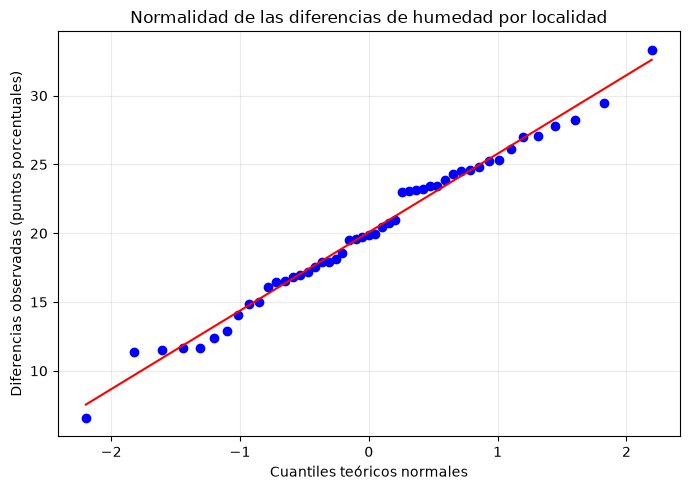


=== SUPUESTOS DE CHI-CUADRADO ===
Frecuencia esperada mínima: 6971.01
Todas las frecuencias esperadas >= 5: True
Nota: las frecuencias esperadas adecuadas no garantizan independencia entre días.


In [12]:

# 7. Verificación de supuestos estadísticos
# Sumativa 1 - Grupo 7

from scipy import stats
import matplotlib.pyplot as plt
from pathlib import Path

# PRUEBA T: normalidad de las diferencias locales
resultado_shapiro = stats.shapiro(diferencias)

print("=== SUPUESTOS DE LA PRUEBA T ===")
print("Localidades:", len(diferencias))
print("Diferencias positivas:", (diferencias > 0).sum())
print(f"Shapiro-Wilk W: {resultado_shapiro.statistic:.4f}")
print(f"Shapiro-Wilk p: {resultado_shapiro.pvalue:.6f}")

if resultado_shapiro.pvalue < 0.05:
    print("Se rechaza la hipótesis de normalidad")
else:
    print("No se rechaza la hipótesis de normalidad")

# Gráfico de diagnóstico de normalidad
fig, ax = plt.subplots(figsize=(7, 5))

stats.probplot(
    diferencias,
    dist="norm",
    plot=ax
)

ax.set_title(
    "Normalidad de las diferencias de humedad por localidad"
)
ax.set_xlabel("Cuantiles teóricos normales")
ax.set_ylabel("Diferencias observadas (puntos porcentuales)")
ax.grid(alpha=0.25)

plt.tight_layout()

carpeta_figuras = Path("../results/02_sumativa1/figures")
carpeta_figuras.mkdir(parents=True, exist_ok=True)

fig.savefig(
    carpeta_figuras / "figura04_diagnostico_normalidad.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# CHI-CUADRADO: frecuencias esperadas
print("\n=== SUPUESTOS DE CHI-CUADRADO ===")

print("Frecuencia esperada mínima:",
      round(frecuencias_esperadas.min(), 2))

print("Todas las frecuencias esperadas >= 5:",
      bool((frecuencias_esperadas >= 5).all()))

print(
    "Nota: las frecuencias esperadas adecuadas "
    "no garantizan independencia entre días."
)



### 4.3. Verificación de supuestos estadísticos

Para complementar las pruebas de hipótesis, revisamos algunos de los supuestos necesarios para interpretar sus resultados.

En la prueba t, aplicamos Shapiro-Wilk a las 49 diferencias de humedad calculadas por localidad. Obtuvimos W = 0,9884 y un valor p = 0,9059.

Como el valor p es superior a 0,05, no encontramos evidencia suficiente para rechazar la normalidad. El gráfico Q-Q también muestra que las diferencias siguen aproximadamente la recta de referencia.

Además, observamos que las 49 localidades presentan diferencias positivas de humedad entre los registros con lluvia posterior y aquellos sin lluvia.

Para la prueba chi-cuadrado, verificamos las frecuencias esperadas y encontramos que la mínima fue de 6.971,01, por lo que se cumple ampliamente el criterio habitual de frecuencias esperadas de al menos 5.

Sin embargo, estas comprobaciones no garantizan que las observaciones sean independientes. Como el dataset contiene registros meteorológicos de días consecutivos y diferentes localidades, todavía es necesario considerar la dependencia temporal y geográfica al interpretar los resultados inferenciales.


In [13]:

# 8. Dependencia temporal de la humedad
# Correlación lag-1 por localidad
# Sumativa 1 - Grupo 7

import pandas as pd
from pathlib import Path

# Trabajar con las variables necesarias
datos_temporales = df[
    ["Location", "Date", "Humidity3pm"]
].copy()

# Verificar formato de fechas
datos_temporales["Date"] = pd.to_datetime(
    datos_temporales["Date"],
    errors="coerce"
)

resultados_temporales = []

# Analizar cada localidad por separado
for localidad, datos_loc in datos_temporales.groupby("Location"):

    # Ordenar cronológicamente
    datos_loc = datos_loc.sort_values("Date")

    # Humedad del día actual
    humedad_actual = datos_loc["Humidity3pm"]

    # Humedad del registro anterior
    humedad_anterior = humedad_actual.shift(1)

    # Considerar solo días realmente consecutivos
    dias_consecutivos = (
        datos_loc["Date"].diff().dt.days == 1
    )

    # Excluir pares con humedad faltante
    mascara = (
        dias_consecutivos
        & humedad_actual.notna()
        & humedad_anterior.notna()
    )

    # Correlación de Pearson entre días consecutivos
    correlacion = humedad_actual.loc[mascara].corr(
        humedad_anterior.loc[mascara]
    )

    resultados_temporales.append({
        "Localidad": localidad,
        "Pares consecutivos": int(mascara.sum()),
        "Correlación lag-1": correlacion
    })

# Crear tabla de resultados
tabla_temporal = pd.DataFrame(resultados_temporales)

# Calcular estadísticas generales
mediana_lag1 = tabla_temporal["Correlación lag-1"].median()
media_lag1 = tabla_temporal["Correlación lag-1"].mean()

print("=== DEPENDENCIA TEMPORAL DE HUMEDAD ===")
print("Localidades:", len(tabla_temporal))
print(f"Mediana correlación lag-1: {mediana_lag1:.4f}")
print(f"Media correlación lag-1: {media_lag1:.4f}")

print("\n=== MENOR CORRELACIÓN TEMPORAL ===")
display(tabla_temporal.nsmallest(5, "Correlación lag-1").round(4))

print("\n=== MAYOR CORRELACIÓN TEMPORAL ===")
display(tabla_temporal.nlargest(5, "Correlación lag-1").round(4))

# Guardar tabla en el repositorio
carpeta_tablas = Path("../results/02_sumativa1/tables")
carpeta_tablas.mkdir(parents=True, exist_ok=True)

tabla_temporal.to_csv(
    carpeta_tablas / "dependencia_temporal_humedad.csv",
    index=False,
    encoding="utf-8-sig"
)


=== DEPENDENCIA TEMPORAL DE HUMEDAD ===
Localidades: 49
Mediana correlación lag-1: 0.5023
Media correlación lag-1: 0.5080

=== MENOR CORRELACIÓN TEMPORAL ===


,Localidad,Pares consecutivos,Correlación lag-1
1,Albany,2301,0.1975
43,Walpole,2936,0.2699
33,Portland,2980,0.3230
15,Hobart,3166,0.3246
35,Sale,2986,0.3283



=== MAYOR CORRELACIÓN TEMPORAL ===


,Localidad,Pares consecutivos,Correlación lag-1
13,Darwin,3185,0.7556
41,Uluru,1569,0.7036
42,WaggaWagga,3005,0.6773
3,AliceSprings,3026,0.6733
25,Nhil,1571,0.6673



### 4.4. Dependencia temporal de las observaciones

Para revisar la dependencia temporal de los registros, calculamos la correlación de Pearson entre la humedad a las 3 PM de días consecutivos dentro de cada localidad.

Se consideraron únicamente pares de registros separados por un día y con información disponible en ambas fechas.

En las 49 localidades obtuvimos una mediana de correlación lag-1 de 0,5023 y una media de 0,5080. Estos valores indican que existe una asociación temporal positiva moderada en las mediciones de humedad.

Sin embargo, encontramos diferencias entre localidades. Darwin presentó una de las correlaciones más altas (0,7556), mientras que Albany registró la menor (0,1975).

Estos resultados muestran que las condiciones de humedad pueden mantenerse relacionadas entre días consecutivos, aunque esta persistencia no tiene la misma intensidad en todas las localidades.

Esta observación es importante para nuestro análisis inferencial, ya que las pruebas clásicas pueden subestimar la incertidumbre cuando las observaciones presentan dependencia.

Por lo tanto, interpretamos los intervalos de confianza y las pruebas de hipótesis considerando esta limitación. El diagnóstico de autocorrelación no corrige por sí mismo la dependencia, pero nos permite identificarla y justificar la necesidad de analizar la sensibilidad de los resultados.


In [14]:

# 9. Análisis de sensibilidad por localidad
# Asociación entre RainToday y RainTomorrow
# Sumativa 1 - Grupo 7

import numpy as np
import pandas as pd
from scipy import stats
from pathlib import Path

# Seleccionar respuestas conocidas
datos_sensibilidad = df.loc[
    df["RainToday"].isin(["No", "Yes"])
    & df["RainTomorrow"].isin(["No", "Yes"]),
    ["Location", "RainToday", "RainTomorrow"]
].copy()

# Convertir lluvia posterior en 1 y 0
datos_sensibilidad["lluvia_manana"] = (
    datos_sensibilidad["RainTomorrow"] == "Yes"
).astype(int)

# Proporción de lluvia posterior por localidad y grupo
tasas_locales = (
    datos_sensibilidad
    .groupby(["Location", "RainToday"])["lluvia_manana"]
    .mean()
    .unstack()
    .reindex(columns=["No", "Yes"])
    .dropna()
)

# Diferencia en puntos porcentuales
tasas_locales["Diferencia_pp"] = (
    tasas_locales["Yes"] - tasas_locales["No"]
) * 100

diferencias_lluvia = tasas_locales["Diferencia_pp"]

# Prueba t sobre las diferencias locales
resultado_sensibilidad = stats.ttest_1samp(
    diferencias_lluvia,
    popmean=0
)

ic_sensibilidad = resultado_sensibilidad.confidence_interval(
    confidence_level=0.95
)

print("=== SENSIBILIDAD POR LOCALIDAD ===")

print("Localidades:", len(diferencias_lluvia))

print(
    "Diferencias positivas:",
    (diferencias_lluvia > 0).sum()
)

print(
    f"Diferencia media: "
    f"{diferencias_lluvia.mean():.2f} puntos porcentuales"
)

print(f"Estadístico t: {resultado_sensibilidad.statistic:.4f}")
print(f"Valor p: {resultado_sensibilidad.pvalue:.6e}")

print(
    f"IC 95%: [{ic_sensibilidad.low:.2f}; "
    f"{ic_sensibilidad.high:.2f}]"
)

# Comprobación de normalidad de las diferencias
shapiro_local = stats.shapiro(diferencias_lluvia)

print(f"Shapiro-Wilk p: {shapiro_local.pvalue:.4f}")

# Mostrar primeras localidades
print("\n=== TASAS LOCALES ===")

display((tasas_locales * pd.Series({
    "No": 100,
    "Yes": 100,
    "Diferencia_pp": 1
})).round(2).head(10))

# Guardar resultados
carpeta_tablas = Path("../results/02_sumativa1/tables")
carpeta_tablas.mkdir(parents=True, exist_ok=True)

tasas_locales.to_csv(
    carpeta_tablas / "sensibilidad_lluvia_por_localidad.csv",
    encoding="utf-8-sig"
)


=== SENSIBILIDAD POR LOCALIDAD ===
Localidades: 49
Diferencias positivas: 49
Diferencia media: 29.11 puntos porcentuales
Estadístico t: 28.0604
Valor p: 1.976297e-31
IC 95%: [27.02; 31.19]
Shapiro-Wilk p: 0.5982

=== TASAS LOCALES ===


RainToday,No,Yes,Diferencia_pp
Location,,,
Adelaide,14.38,47.04,32.66
Albany,21.83,48.38,26.55
Albury,14.65,43.41,28.77
AliceSprings,4.99,42.74,37.75
BadgerysCreek,14.14,42.66,28.51
Ballarat,19.07,45.24,26.17
Bendigo,13.94,38.61,24.67
Brisbane,16.06,44.74,28.68
Cairns,17.60,61.53,43.93



### 4.5. Análisis de sensibilidad por localidad

Para complementar la prueba chi-cuadrado, realizamos un análisis de sensibilidad considerando las 49 localidades como unidades de comparación.

Calculamos, dentro de cada localidad, la proporción de lluvia al día siguiente según si había llovido o no durante el día anterior. Posteriormente, obtuvimos la diferencia entre ambas proporciones.

Encontramos diferencias positivas en las 49 localidades, con una diferencia media de 29,11 puntos porcentuales.

Al aplicar una prueba t de una muestra sobre estas diferencias, obtuvimos un estadístico t = 28,06 y un valor p inferior a 0,001. El intervalo de confianza nominal del 95 % se situó entre 27,02 y 31,19 puntos porcentuales.

También revisamos la normalidad de las diferencias mediante Shapiro-Wilk, obteniendo un valor p = 0,5982. Por lo tanto, no encontramos evidencia suficiente para rechazar este supuesto.

Al comparar ambos enfoques, observamos que el análisis agrupado presenta una diferencia de 31,22 puntos porcentuales, mientras que el análisis por localidades alcanza 29,11 puntos.

Aunque los valores no son idénticos, ambos procedimientos muestran una asociación positiva entre lluvia durante el día y lluvia posterior.

Este resultado refuerza la interpretación descriptiva, pero no demuestra causalidad ni elimina completamente los posibles efectos de la dependencia espacial, temporal o de la cobertura desigual de los registros.


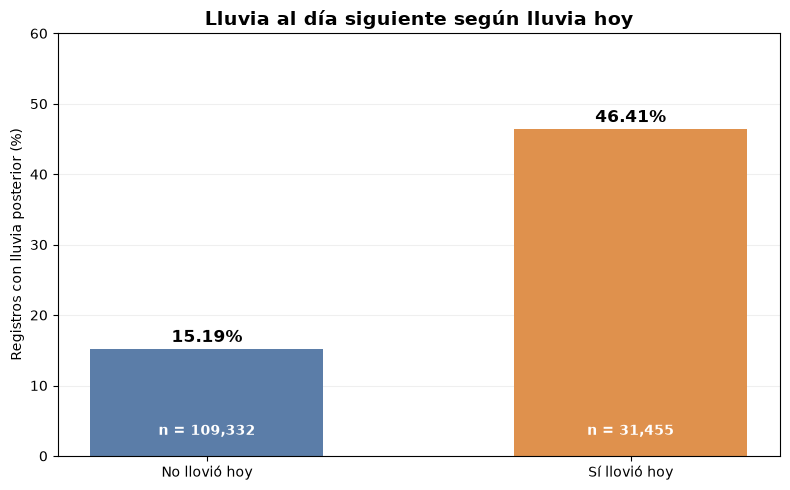

In [15]:

# Figura 5. Lluvia al día siguiente según lluvia hoy
# Sumativa 1 - Grupo 7

import matplotlib.pyplot as plt
from pathlib import Path

# Porcentajes obtenidos en la prueba chi-cuadrado
categorias = ["No llovió hoy", "Sí llovió hoy"]

valores = [
    porcentajes.loc["No", "Yes"],
    porcentajes.loc["Yes", "Yes"]
]

# Cantidad de registros utilizados por grupo
totales = tabla_contingencia.sum(axis=1)

fig, ax = plt.subplots(figsize=(8, 5))

barras = ax.bar(
    categorias,
    valores,
    color=["#5B7DA8", "#DF914D"],
    width=0.55
)

# Mostrar porcentajes sobre las barras
for barra, valor in zip(barras, valores):
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        valor + 1,
        f"{valor:.2f}%",
        ha="center",
        fontsize=12,
        fontweight="bold"
    )

ax.set_title(
    "Lluvia al día siguiente según lluvia hoy",
    fontsize=14,
    fontweight="bold"
)

ax.set_ylabel("Registros con lluvia posterior (%)")
ax.set_ylim(0, 60)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

# Tamaños de cada grupo
for i, grupo in enumerate(["No", "Yes"]):
    ax.text(
        i, 3,
        f"n = {totales.loc[grupo]:,}",
        ha="center",
        color="white",
        fontweight="bold"
    )

plt.tight_layout()

# Guardar figura
carpeta_figuras = Path("../results/02_sumativa1/figures")
carpeta_figuras.mkdir(parents=True, exist_ok=True)

fig.savefig(
    carpeta_figuras / "figura05_lluvia_hoy_manana.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [17]:

# 10. Validación final del proyecto
# Sumativa 1 - Grupo 7

from pathlib import Path

# Ubicación de las carpetas del proyecto
raiz = Path.cwd().parent

carpeta_figuras = raiz / "results/02_sumativa1/figures"
carpeta_tablas = raiz / "results/02_sumativa1/tables"

# Archivos que esperamos encontrar
figuras_esperadas = [
    "figura01_histograma_rainfall.png",
    "figura02_boxplot_humedad.png",
    "figura03_correlaciones.png",
    "figura04_diagnostico_normalidad.png",
    "figura05_lluvia_hoy_manana.png"
]

tablas_esperadas = [
    "dependencia_temporal_humedad.csv",
    "intervalo_proporcion_lluvia.csv",
    "intervalos_medias_localidades.csv",
    "matriz_correlaciones_spearman.csv",
    "n_pares_correlaciones.csv",
    "porcentajes_lluvia_hoy_manana.csv",
    "proporcion_lluvia_localidades.csv",
    "sensibilidad_lluvia_por_localidad.csv",
    "tabla_contingencia_lluvia.csv"
]

print("=== VALIDACIÓN FINAL DEL PROYECTO ===")

# Comprobar dataset
assert len(df) == 145460
print("Dataset: 145460 registros - OK")

# Comprobar figuras
print("\n=== FIGURAS ===")

for nombre in figuras_esperadas:
    archivo = carpeta_figuras / nombre
    assert archivo.is_file(), f"Falta: {nombre}"
    assert archivo.stat().st_size > 0, f"Archivo vacío: {nombre}"
    print("OK:", nombre)

# Comprobar tablas
print("\n=== TABLAS ===")

for nombre in tablas_esperadas:
    archivo = carpeta_tablas / nombre
    assert archivo.is_file(), f"Falta: {nombre}"
    assert archivo.stat().st_size > 0, f"Archivo vacío: {nombre}"
    print("OK:", nombre)

print("\n=== RESUMEN ===")
print("Figuras verificadas:", len(figuras_esperadas))
print("Tablas verificadas:", len(tablas_esperadas))

print("\nVALIDACIÓN BÁSICA COMPLETADA CORRECTAMENTE")


=== VALIDACIÓN FINAL DEL PROYECTO ===
Dataset: 145460 registros - OK

=== FIGURAS ===
OK: figura01_histograma_rainfall.png
OK: figura02_boxplot_humedad.png
OK: figura03_correlaciones.png
OK: figura04_diagnostico_normalidad.png
OK: figura05_lluvia_hoy_manana.png

=== TABLAS ===
OK: dependencia_temporal_humedad.csv
OK: intervalo_proporcion_lluvia.csv
OK: intervalos_medias_localidades.csv
OK: matriz_correlaciones_spearman.csv
OK: n_pares_correlaciones.csv
OK: porcentajes_lluvia_hoy_manana.csv
OK: proporcion_lluvia_localidades.csv
OK: sensibilidad_lluvia_por_localidad.csv
OK: tabla_contingencia_lluvia.csv

=== RESUMEN ===
Figuras verificadas: 5
Tablas verificadas: 9

VALIDACIÓN BÁSICA COMPLETADA CORRECTAMENTE


In [18]:

# 11. Documentación del entorno de ejecución
# Sumativa 1 - Grupo 7

import sys
from pathlib import Path
from importlib.metadata import version

# Ubicación del proyecto
raiz = Path.cwd().parent
carpeta_docs = raiz / "docs"
carpeta_docs.mkdir(parents=True, exist_ok=True)

# Bibliotecas utilizadas
paquetes = [
    "numpy",
    "pandas",
    "scipy",
    "matplotlib",
    "seaborn",
    "ipykernel"
]

# Preparar documentación
lineas = [
    "# Entorno de ejecución - Sumativa 1",
    "",
    "## Configuración utilizada",
    "",
    f"- Python: {sys.version.split()[0]}",
    "- Kernel: MCDI500 Grupo 7",
    "- Sistema operativo: Windows",
    "- Estado: entorno alternativo provisional",
    "",
    "## Bibliotecas verificadas",
    ""
]

for paquete in paquetes:
    numero_version = version(paquete)
    lineas.append(f"- {paquete}: {numero_version}")

lineas.extend([
    "",
    "## Reproducibilidad",
    "",
    "El análisis utiliza el dataset original weatherAUS.csv.",
    "El archivo debe estar en data/raw/.",
    "",
    "Las dependencias generales se encuentran en",
    "requirements.txt, en la raíz del repositorio.",
    "",
    "El notebook se ejecutó de principio a fin en JupyterLab.",
    "Se comprobaron 5 figuras y 9 tablas de resultados.",
    "",
    "Este entorno pertenece originalmente a MCDI500.",
    "Su uso para MCDI501 es provisional.",
    "",
    "Antes de reproducir el trabajo en otro computador,",
    "se deben instalar las dependencias y validar",
    "la ejecución completa en un entorno independiente.",
    ""
])

# Guardar archivo Markdown
ruta_documento = (
    carpeta_docs / "entorno_sumativa1_jorge.md"
)

ruta_documento.write_text(
    "\n".join(lineas),
    encoding="utf-8"
)

print("=== DOCUMENTACIÓN DEL ENTORNO ===")
print("Archivo creado:", ruta_documento.name)
print("Python:", sys.version.split()[0])
print("Bibliotecas documentadas:", len(paquetes))
print("Documentación generada correctamente.")


=== DOCUMENTACIÓN DEL ENTORNO ===
Archivo creado: entorno_sumativa1_jorge.md
Python: 3.13.0
Bibliotecas documentadas: 6
Documentación generada correctamente.
